# Create a DEG list of the  healthy vs primary tumours in the data from NR Atlas
## Looking at all the DCs here first

Performing DEG analysis (limma, R) on all cancer data from the NR_atlas all DC data. Using code from NR's 2025-01-13-Pseudo_Cancer_DEGS.ipynb

Date: 13.04.2026

In [1]:
### install packages required

library(Seurat)

Loading required package: SeuratObject

Loading required package: sp



‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.5; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t




In [2]:
library(sceasy)
library(reticulate)
use_condaenv('R_env')

Loading required package: reticulate



In [3]:
install.packages("edgeR")

Warning message:
“package ‘edgeR’ is not available for this version of R

A version of this package for your version of R might be available elsewhere,
see the ideas at
https://cran.r-project.org/doc/manuals/r-patched/R-admin.html#Installing-packages”


In [4]:
library(limma)
library(edgeR)
library(dplyr)
library(ggplot2)
library(ggrepel)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## Convert anndata object to seurat object

In [5]:
#Set working directory
getwd()
setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/R_Jupyter_Analysis")

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code"

In [6]:
data <- '/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250617_AllDC_bbknn.h5ad' #this dataset has all the cancer atlas, DC data and primary and metastatic info

In [7]:
head(data)

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250617_AllDC_bbknn.h5ad"

In [8]:
sceasy::convertFormat(data, from="anndata", to="seurat", outFile='/scratch/user/uqlbukat/NRAtlas_analysis_2026/AllDC_bbknndata.RDS')

X -> counts



An object of class Seurat 
1746 features across 29887 samples within 1 assay 
Active assay: RNA (1746 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

# Read in converted data

In [9]:
data <- readRDS('/scratch/user/uqlbukat/NRAtlas_analysis_2026/AllDC_bbknndata.RDS')

Explore the data structure

In [10]:
head(data)

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143,2659,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15629172,0.28721189,0.462408497,0.36365491
GSE215120_AM1_ACACTGATCCACTGGG-1,18333,2845,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.18922702,0.26297257,0.329305354,0.54009108
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581,2182,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.13527090,0.03988112,0.149324713,0.03211458
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015,1488,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.36721915,-0.12373999,0.004747235,0.27328160
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642,4010,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.32900991,-0.25416563,0.017663713,0.11923450
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833,2074,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.14672113,0.08149318,0.174721746,-0.17654256
GSE215120_AM1_ACTGAGTCAGGCTGAA-1,7117,1505,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,3.259800,skin,primary tumour,Acral Melanoma,⋯,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15998438,-0.05433711,-0.048045593,0.74123969
GSE215120_AM1_ACTGTCCGTCTCTTAT-1,7875,1515,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.930159,skin,primary tumour,Acral Melanoma,⋯,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.15336146,-0.02565772,0.004267385,0.53398699
GSE215120_AM1_ACTTGTTTCTGAAAGA-1,7887,1846,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.738684,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.05677931,0.42842232,0.365930736,-0.08318085


In [11]:
class(data)

[1] "Seurat"
attr(,"package")
[1] "SeuratObject"

In [12]:
#Basic Structure
slotNames(data)

[1] "assays"       "meta.data"    "active.assay" "active.ident" "graphs"      
 [6] "neighbors"    "reductions"   "images"       "project.name" "misc"        
[11] "version"      "commands"     "tools"

In [13]:
#Metadata and cells
colnames(data)           # cell IDs
head(colnames(data))
head(data@meta.data)

[1] "GSE215120_AM1_AAATGCCCAGAGCCAA-1"                                                  
    [2] "GSE215120_AM1_ACACTGATCCACTGGG-1"                                                  
    [3] "GSE215120_AM1_ACAGCCGCAAACCTAC-1"                                                  
    [4] "GSE215120_AM1_ACCAGTAAGACTGGGT-1"                                                  
    [5] "GSE215120_AM1_ACGTCAACAAGGACTG-1"                                                  
    [6] "GSE215120_AM1_ACGTCAATCCGCATCT-1"                                                  
    [7] "GSE215120_AM1_ACTGAGTCAGGCTGAA-1"                                                  
    [8] "GSE215120_AM1_ACTGTCCGTCTCTTAT-1"                                                  
    [9] "GSE215120_AM1_ACTTGTTTCTGAAAGA-1"                                                  
   [10] "GSE215120_AM1_AGAGCTTGTACAGTTC-1"                                                  
   [11] "GSE215120_AM1_AGGGATGGTTTGTGTG-1"                                                  
   [12] "GSE215120_AM1_AGGTCATAGTACGCGA-1"                                                  
   [13] "GSE215120_AM1_AGGTCCGCATTCTTAC-1"                                                  
   [14] "GSE215120_AM1_ATAACGCGTAGCGCTC-1"                                                  
   [15] "GSE215120_AM1_ATAGACCCATTACCTT-1"                                                  
   [16] "GSE215120_AM1_ATCCACCCAGACGCTC-1"                                                  
   [17] "GSE215120_AM1_ATTGGTGAGTCTCGGC-1"                                                  
   [18] "GSE215120_AM1_CACTCCACACTAGTAC-1"                                                  
   [19] "GSE215120_AM1_CAGAGAGTCTTCATGT-1"                                                  
   [20] "GSE215120_AM1_CAGCATAGTGCGGTAA-1"                                                  
   [21] "GSE215120_AM1_CAGCATATCTGCCAGG-1"                                                  
   [22] "GSE215120_AM1_CAGCGACTCTCAACTT-1"                                                  
   [23] "GSE215120_AM1_CATGCCTGTTGGTTTG-1"                                                  
   [24] "GSE215120_AM1_CCATGTCCACCGCTAG-1"                                                  
   [25] "GSE215120_AM1_CCCTCCTGTCCAGTGC-1"                                                  
   [26] "GSE215120_AM1_CCGGGATTCAACACAC-1"                                                  
   [27] "GSE215120_AM1_CGAGCCATCCGAATGT-1"                                                  
   [28] "GSE215120_AM1_CGTCAGGAGGAGTACC-1"                                                  
   [29] "GSE215120_AM1_CGTGTAAGTTCGCTAA-1"                                                  
   [30] "GSE215120_AM1_CTAGTGAGTAGCACGA-1"                                                  
   [31] "GSE215120_AM1_CTAGTGATCACCCGAG-1"                                                  
   [32] "GSE215120_AM1_CTGCCTACAGCTGTTA-1"                                                  
   [33] "GSE215120_AM1_CTGCCTAGTTAAGTAG-1"                                                  
   [34] "GSE215120_AM1_CTGCTGTGTCGTCTTC-1"                                                  
   [35] "GSE215120_AM1_CTGTGCTAGTCGTACT-1"                                                  
   [36] "GSE215120_AM1_GACGGCTCACAAGTAA-1"                                                  
   [37] "GSE215120_AM1_GCAGTTATCATGTCCC-1"                                                  
   [38] "GSE215120_AM1_GCGAGAACACATAACC-1"                                                  
   [39] "GSE215120_AM1_GCGCAACTCGTAGGTT-1"                                                  
   [40] "GSE215120_AM1_GCGCAGTGTAACGACG-1"                                                  
   [41] "GSE215120_AM1_GCGCCAAAGAGAACAG-1"                                                  
   [42] "GSE215120_AM1_GCGCCAACAAGTAATG-1"                                                  
   [43] "GSE215120_AM1_GCGGGTTAGACTAGAT-1"                                                  
   [4

[1] "GSE215120_AM1_AAATGCCCAGAGCCAA-1" "GSE215120_AM1_ACACTGATCCACTGGG-1"
[3] "GSE215120_AM1_ACAGCCGCAAACCTAC-1" "GSE215120_AM1_ACCAGTAAGACTGGGT-1"
[5] "GSE215120_AM1_ACGTCAACAAGGACTG-1" "GSE215120_AM1_ACGTCAATCCGCATCT-1"

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143,2659,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1562917,0.28721189,0.462408497,0.36365491
GSE215120_AM1_ACACTGATCCACTGGG-1,18333,2845,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1892270,0.26297257,0.329305354,0.54009108
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581,2182,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1352709,0.03988112,0.149324713,0.03211458
GSE215120_AM1_ACCAGTAAGACTGGGT-1,8015,1488,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.033687,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.3672192,-0.12373999,0.004747235,0.27328160
GSE215120_AM1_ACGTCAACAAGGACTG-1,25642,4010,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.835192,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC1,primary tumour,Acral Melanoma,MEL,Treatment naive,0.3290099,-0.25416563,0.017663713,0.11923450
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833,2074,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,⋯,10x3',cDC2,primary tumour,Acral Melanoma,MEL,Treatment naive,0.1467211,0.08149318,0.174721746,-0.17654256


In [14]:
#Check cancer type in object
unique(data@meta.data$cancer_type)

[1] Acral Melanoma        Cutaneous Melanoma    TNBC                 
 [4] HNSCC                 LUAD                  Healthy              
 [7] LUSC                  HER2 Breast Cancer    ER Breast Cancer     
[10] melanoma brain mets   HGSOC                 DCIS                 
[13] IDC                   ER breast cancer      BRCA1 TNBC           
[16] ER breast cancer mets HER2 breast cancer    PDAC                 
[19] CRC                   CRC - Healthy         breast cancer        
[22] Glioblastoma          Metastatic Melanoma   GAC liver mets       
[25] GAC ovarian mets      GAC primary           PDAC Liver mets      
[28] PDAC Lung mets        PDAC primary          CRC mets             
[31] HCC                   PC                    GBM                  
[34] iCCA                  healthy               NSCLC                
[37] NPC                   Diffuse-type GC Sup   Diffuse-type GC Deep 
39 Levels: Acral Melanoma BRCA1 TNBC CRC CRC - Healthy ... melanoma brain mets

In [15]:
#Check sample types (primary or met)
unique(data@meta.data$sample_type_major)
unique(data@meta.data$sample_type_major2)

[1] primary tumour    metastatic tumour local recurrence  healthy          
[5] ascites          
5 Levels: ascites healthy local recurrence ... primary tumour

[1] primary tumour    metastatic tumour healthy           ascites          
Levels: ascites healthy metastatic tumour primary tumour

In [16]:
table(data@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
             3513              3364              5674             17336 

In [17]:
#Assays and features
Assays(data)             # list assays
DefaultAssay(data)
rownames(data)           # gene names

[1] "RNA"

[1] "RNA"

[1] "KLHL17"     "HES4"       "ISG15"      "TNFRSF18"   "TNFRSF4"   
   [6] "MORN1"      "ACOT7"      "ERRFI1"     "SLC2A5"     "GPR157"    
  [11] "FBXO2"      "AGTRAP"     "PDPN"       "PRDM2"      "EPHA2"     
  [16] "PADI2"      "NBL1"       "HSPG2"      "C1QA"       "C1QC"      
  [21] "C1QB"       "LUZP1"      "TCEA3"      "ID3"        "FUCA1"     
  [26] "STPG1"      "RUNX3"      "LDLRAP1"    "STMN1"      "SFN"       
  [31] "SLC9A1"     "IFI6"       "SMPDL3B"    "RAB42"      "SDC3"      
  [36] "FABP3"      "SERINC2"    "LCK"        "MARCKSL1"   "FAM229A"   
  [41] "KIAA1522"   "ZC3H12A"    "POU3F1"     "CDC20"      "PTPRF"     
  [46] "MKNK1"      "PDZK1IP1"   "DHCR24"     "DAB1"       "TACSTD2"   
  [51] "JUN"        "NFIA"       "EFCAB7"     "ROR1"       "PDE4B"     
  [56] "GADD45A"    "WLS"        "CTH"        "NEGR1"      "ST6GALNAC3"
  [61] "AK5"        "DNAJB4"     "IFI44L"     "MCOLN2"     "ODF2L"     
  [66] "GBP1"       "GBP2"       "GBP4"       "GBP5"       "CDC7"      
  [71] "CNN3"       "DPYD"       "VCAM1"      "PRMT6"      "KIAA1324"  
  [76] "GSTM3"      "CSF1"       "KCNA3"      "DENND2D"    "MAGI3"     
  [81] "OLFML3"     "BCAS2"      "CD2"        "NBPF15"     "TXNIP"     
  [86] "FMO5"       "BCL9"       "PDE4DIP"    "HIST2H3D"   "HIST2H2AB" 
  [91] "C1orf54"    "ECM1"       "CTSK"       "C1orf56"    "SELENBP1"  
  [96] "CGN"        "TDRKH"      "TCHH"       "S100A9"     "S100A12"   
 [101] "S100A8"     "S100A7"     "S100A6"     "S100A4"     "S100A2"    
 [106] "S100A16"    "S100A14"    "S100A13"    "S100A1"     "RAB13"     
 [111] "ATP8B2"     "EFNA1"      "MUC1"       "RAB25"      "LMNA"      
 [116] "IQGAP3"     "NES"        "CRABP2"     "SH2D2A"     "ETV3"      
 [121] "CD1A"       "CD1C"       "CD1B"       "CD1E"       "PYHIN1"    
 [126] "FCER1A"     "SLAMF6"     "CD84"       "SLAMF1"     "SLAMF7"    
 [131] "LY9"        "USP21"      "FCGR2A"     "HSPA6"      "FCGR3A"    
 [136] "FCGR2B"     "NOS1AP"     "RGS5"       "PBX1"       "CD247"     
 [141] "CREG1"      "TNFSF18"    "TNFSF4"     "RABGAP1L"   "RASAL2"    
 [146] "ABL2"       "XPR1"       "IER5"       "GLUL"       "RGS16"     
 [151] "NPL"        "LAMC1"      "RGL1"       "IVNS1ABP"   "PTGS2"     
 [156] "CFH"        "ASPM"       "MIR181A1HG" "KIF14"      "TNNT2"     
 [161] "LAD1"       "ELF3"       "UBE2T"      "KDM5B"      "CHI3L1"    
 [166] "CHIT1"      "BTG2"       "ZC3H11A"    "ZBED6"      "PPP1R15B"  
 [171] "CDK18"      "SLC41A1"    "IL10"       "PIGR"       "PFKFB2"    
 [176] "YOD1"       "PLXNA2"     "LAMB3"      "G0S2"       "ATF3"      
 [181] "PTPN14"     "CENPF"      "DNAH14"     "ENAH"       "EPHX1"     
 [186] "TMEM63A"    "CDC42BPA"   "ARV1"       "FAM89A"     "TBCE"      
 [191] "GNG4"       "LYST"       "NID1"       "GPR137B"    "EDARADD"   
 [196] "ACTN2"      "KMO"        "AKT3"       "KIF26B"     "SMYD3"     
 [201] "NLRP3"      "ZNF692"     "PGBD2"      "SH3YL1"     "RSAD2"     
 [206] "LINC00299"  "RRM2"       "FAM49A"     "SDC1"       "RHOB"      
 [211] "ADCY3"      "KRTCAP3"    "CCDC121"    "TRMT61B"    "LBH"       
 [216] "CDC42EP3"   "CYP1B1"     "SLC8A1"     "EML4"       "ZFP36L2"   
 [221] "PRKCE"      "EPAS1"      "EPCAM"      "FBXO11"     "SPTBN1"    
 [226] "UGP2"       "PELI1"      "SPRED2"     "MXD1"       "PCYOX1"    
 [231] "CLEC4F"     "CD207"      "MCEE"       "SPR"        "EGR4"      
 [236] "MTHFD2"     "RTKN"       "RETSAT"     "SFTPB"      "GNLY"      
 [241] "ATOH8"      "ST3GAL5"    "CD8A"       "CD8B"       "EIF2AK3"   
 [246] "MAL"        "ANKRD36C"   "ADRA2B"     "ASTL"       "DUSP2"     
 [251] "NCAPH"      "FAHD2B"     "ANKRD36"    "AC159540.1" "ZAP70"     
 [256] "TMEM131"    "AFF3"       "PDCL3"      "TBC1D8"     "MAP4K4"    
 [261] "IL1R2"      "IL1R1"      "RANBP2"     "MERTK"      "SLC20A1"   
 [266] "CKAP2L"     "IL1A"       "IL1B"       "IL1RN"      "MARCO"     
 [271] "STEAP3"     "EPB41L5"    "NCKAP5"     "MGAT5"      "TMEM163"   
 [276] "ZRANB3"     "CXCR4"      "KYNU"    

In [18]:
# Check counts and normalized data
data[1:5, 1:5]           # small slice
GetAssayData(data, layer = "counts")[1:5, 1:5]
GetAssayData(data, layer = "data")[1:5, 1:5]

An object of class Seurat 
5 features across 5 samples within 1 assay 
Active assay: RNA (5 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

5 x 5 sparse Matrix of class "dgCMatrix"
         GSE215120_AM1_AAATGCCCAGAGCCAA-1 GSE215120_AM1_ACACTGATCCACTGGG-1
KLHL17                        -0.06440404                      -0.06569169
HES4                           2.14238723                       3.57810768
ISG15                          0.17844485                       2.03785219
TNFRSF18                       1.34343664                       3.09841588
TNFRSF4                        3.33262038                       2.65246409
         GSE215120_AM1_ACAGCCGCAAACCTAC-1 GSE215120_AM1_ACCAGTAAGACTGGGT-1
KLHL17                         -0.0683830                      -0.06572413
HES4                            4.4948791                      -0.28542355
ISG15                           2.6584123                       0.90408332
TNFRSF18                       -0.2248601                      -0.22687196
TNFRSF4                        -0.2563366                      -0.25268703
         GSE215120_AM1_ACGTCAACAAGGACTG-1
KLHL17           

5 x 5 sparse Matrix of class "dgCMatrix"
         GSE215120_AM1_AAATGCCCAGAGCCAA-1 GSE215120_AM1_ACACTGATCCACTGGG-1
KLHL17                        -0.06440404                      -0.06569169
HES4                           2.14238723                       3.57810768
ISG15                          0.17844485                       2.03785219
TNFRSF18                       1.34343664                       3.09841588
TNFRSF4                        3.33262038                       2.65246409
         GSE215120_AM1_ACAGCCGCAAACCTAC-1 GSE215120_AM1_ACCAGTAAGACTGGGT-1
KLHL17                         -0.0683830                      -0.06572413
HES4                            4.4948791                      -0.28542355
ISG15                           2.6584123                       0.90408332
TNFRSF18                       -0.2248601                      -0.22687196
TNFRSF4                        -0.2563366                      -0.25268703
         GSE215120_AM1_ACGTCAACAAGGACTG-1
KLHL17           

In [19]:
#Check DC types in object
unique(data@meta.data$NR_annotations_simple)

[1] cDC2   cDC1   mregDC
Levels: cDC1 cDC2 mregDC

In [20]:
table(data@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  6670  17166   6051 

Visualise the mreg DC UMAP in the Cancer dataset

In [21]:
#my_colors <- c("cDC1" = "#FF0000", "cDC2" = "#00FF00", "mregDC" = "")

my_cols <- c("mregDC" = "#8C564B", "cDC1" = "#E377C2", "cDC2" = "#AA40FC")

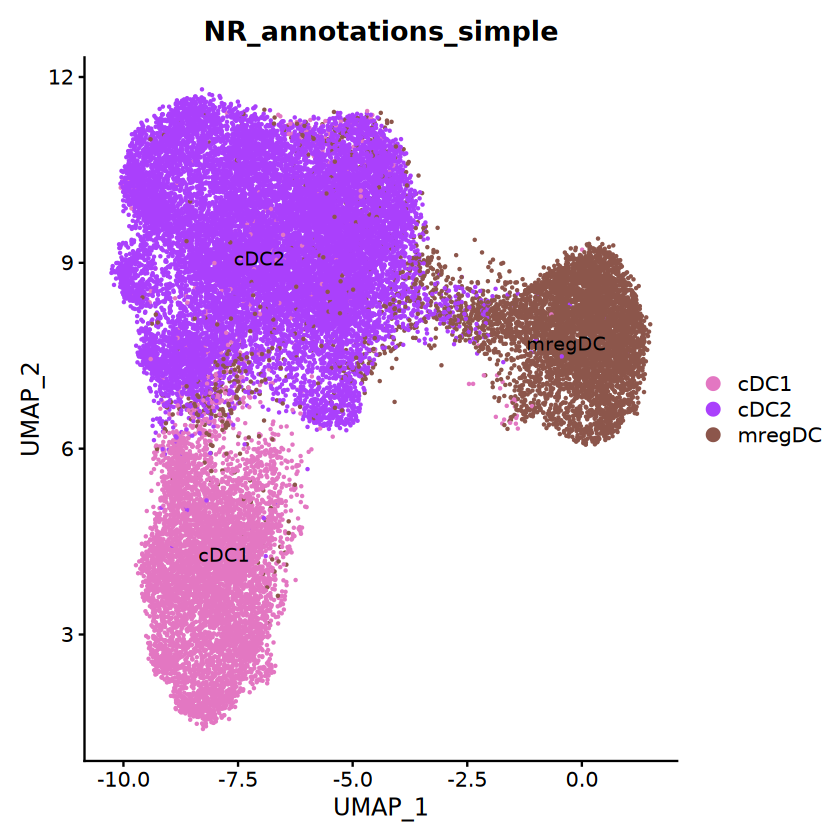

In [22]:
#FeaturePlot(oc.data, features = features)
DimPlot(data, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

# Create a DEG list (primary vs mets) of the mregDCs 

Use the code generated from Perplexity (23.3.26)

In [23]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "mregDC"

data_mregDC <- subset(
  x = data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [24]:
data_mregDC

An object of class Seurat 
1746 features across 6051 samples within 1 assay 
Active assay: RNA (1746 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

In [25]:
#Confirm that our subsetted data only has our cells of interest
table(data_mregDC@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0      0   6051 

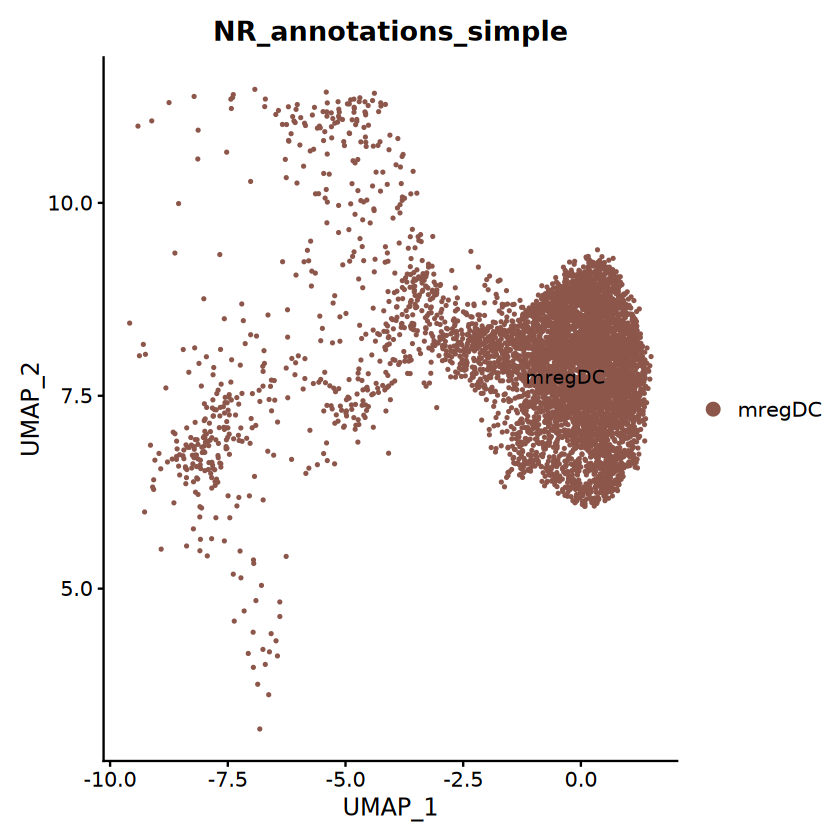

In [26]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_mregDC, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

In [27]:
# Set the cell identities to the "sample" metadata column
Idents(data_mregDC) <- data_mregDC@meta.data$sample_type_major2

# Confirm
table(Idents(data_mregDC))


          ascites           healthy metastatic tumour    primary tumour 
              246               471              1103              4231 

In [28]:
#subset further to only have primary and metastatic data
data_mregDC_sub <- subset(data_mregDC,
subset = sample_type_major2 %in% c("healthy", "metastatic tumour"))


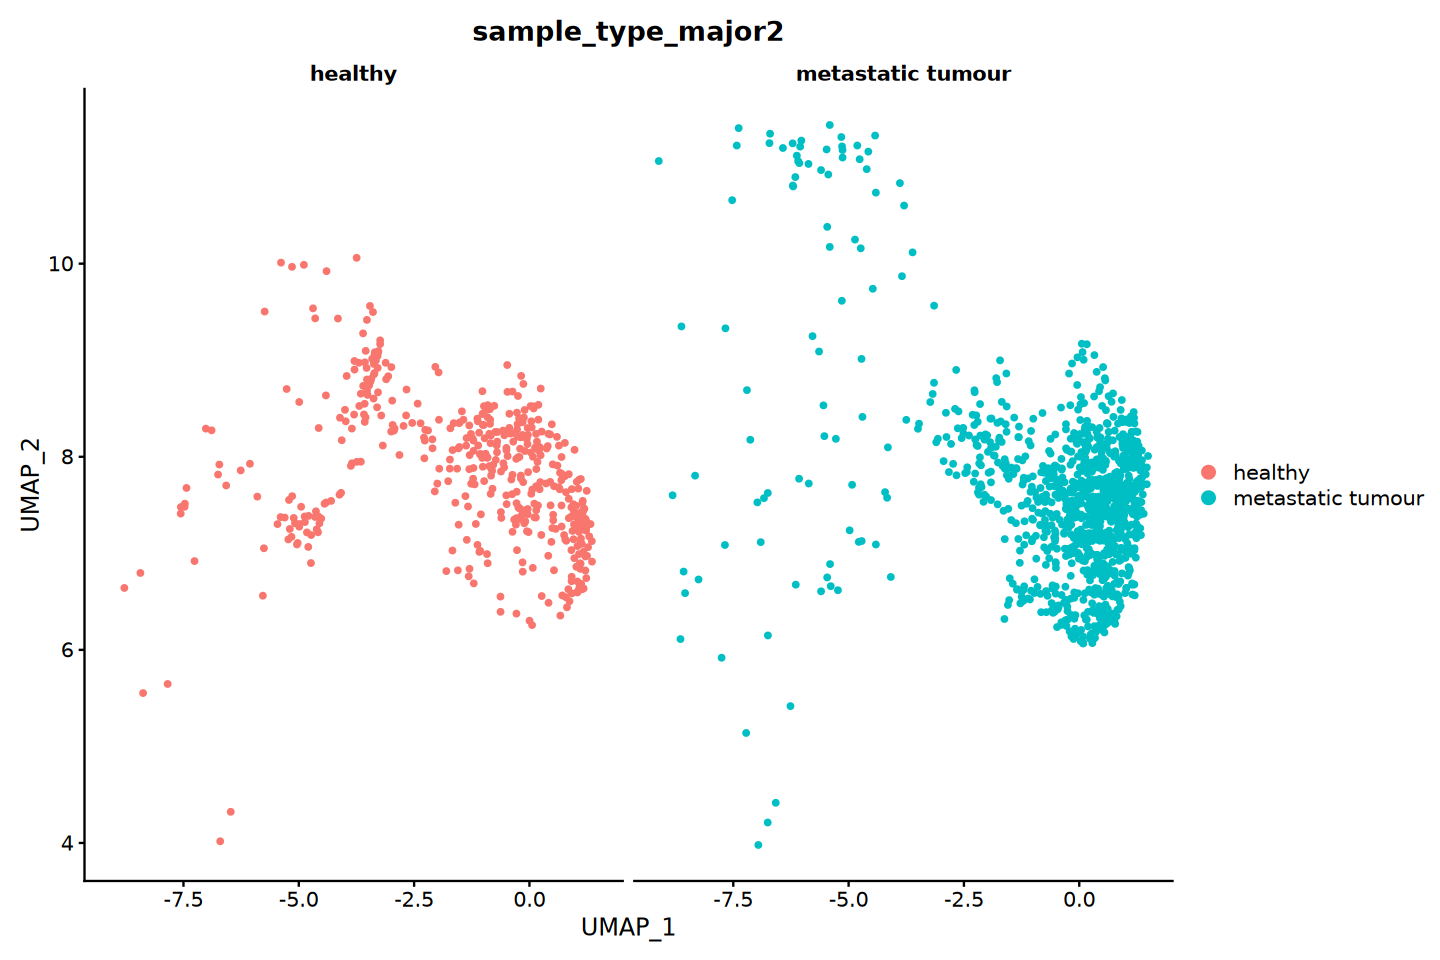

In [29]:
options(repr.plot.width= 12, repr.plot.height= 8)
DimPlot(data_mregDC_sub, reduction = "umap", group.by = "sample_type_major2", repel = TRUE, split.by = "sample_type_major2")

In [30]:
table(data_mregDC_sub@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0      0   1574 

In [31]:
# Confirm the counts in the subsetted data
#Set the cell identities to the "sample" metadata column
Idents(data_mregDC_sub) <- data_mregDC_sub@meta.data$sample_type_major2

# Confirm
table(Idents(data_mregDC_sub))


          healthy metastatic tumour 
              471              1103 

In [32]:
#Confirm that our subsetted data only has our states of interest
table(data_mregDC_sub@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
                0               471              1103                 0 

Run Differential Expression between two states

In [33]:
# Define which two states to compare
group1 <- "healthy"   # upregulated genes will be positive logFC in this group
group2 <- "metastatic tumour"

deg_res_mreg <- FindMarkers(
  object = data_mregDC_sub,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25,   # only genes with |log2FC| >= 0.25
  max.cells.per.ident = Inf,
  random.seed = 777    
)

head(deg_res_mreg)

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”
For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown once per session



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
KIF2A,8.391550e-35,-1.5403342,0.446,0.741,1.465165e-31
PIK3R5,3.865636e-31,0.4814712,0.389,0.186,6.749400e-28
XYLT1,1.238585e-30,1.5678858,0.567,0.311,2.162570e-27
DENND4A,3.240645e-28,1.0955000,0.463,0.284,5.658167e-25
FNDC3B,1.469301e-27,1.3630123,0.397,0.199,2.565399e-24
ATP1B3,1.473209e-27,1.9274458,0.573,0.311,2.572224e-24


deg_res will be a data frame with columns like:

* p_val

* avg_log2FC (or avg_logFC depending on Seurat version)

* pct.1 and pct.2

* p_val_adj

In [34]:
deg_sig_mreg <- subset(
  deg_res_mreg,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_mreg[order(deg_sig_mreg$avg_log2FC, decreasing = TRUE), ], n = 10)


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TF,3.448599e-21,9.644828,0.180,0.044,6.021253e-18
RBFOX3,1.478770e-05,9.465891,0.115,0.005,2.581933e-02
CCL20,1.587144e-07,4.874431,0.106,0.030,2.771154e-04
EREG,3.903444e-13,4.723524,0.212,0.043,6.815414e-10
AHRR,2.170228e-12,4.611467,0.488,0.303,3.789218e-09
LPXN,1.844948e-12,3.934735,0.242,0.084,3.221280e-09
CCL3,3.695823e-07,3.905956,0.151,0.093,6.452906e-04
ARMC9,1.335448e-06,3.815863,0.106,0.018,2.331691e-03
ANKRD28,6.106889e-13,3.722696,0.248,0.083,1.066263e-09


In [35]:
deg_sig_mreg

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
KIF2A,8.391550e-35,-1.5403342,0.446,0.741,1.465165e-31
XYLT1,1.238585e-30,1.5678858,0.567,0.311,2.162570e-27
DENND4A,3.240645e-28,1.0955000,0.463,0.284,5.658167e-25
FNDC3B,1.469301e-27,1.3630123,0.397,0.199,2.565399e-24
ATP1B3,1.473209e-27,1.9274458,0.573,0.311,2.572224e-24
ZHX2,3.016118e-26,1.6143942,0.480,0.270,5.266142e-23
RASSF4,1.969023e-25,-1.2214157,0.597,0.791,3.437914e-22
ABTB2,7.546314e-25,1.3360238,0.340,0.182,1.317586e-21
TIAM1,3.441370e-24,0.7686451,0.318,0.143,6.008632e-21


Quick visualisation

In [36]:
top_genes_mreg <- rownames(head(deg_sig_mreg[order(deg_sig_mreg$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_mreg


[1] "TF"      "RBFOX3"  "CCL20"   "EREG"    "AHRR"    "LPXN"    "CCL3"   
 [8] "ARMC9"   "ANKRD28" "KMO"

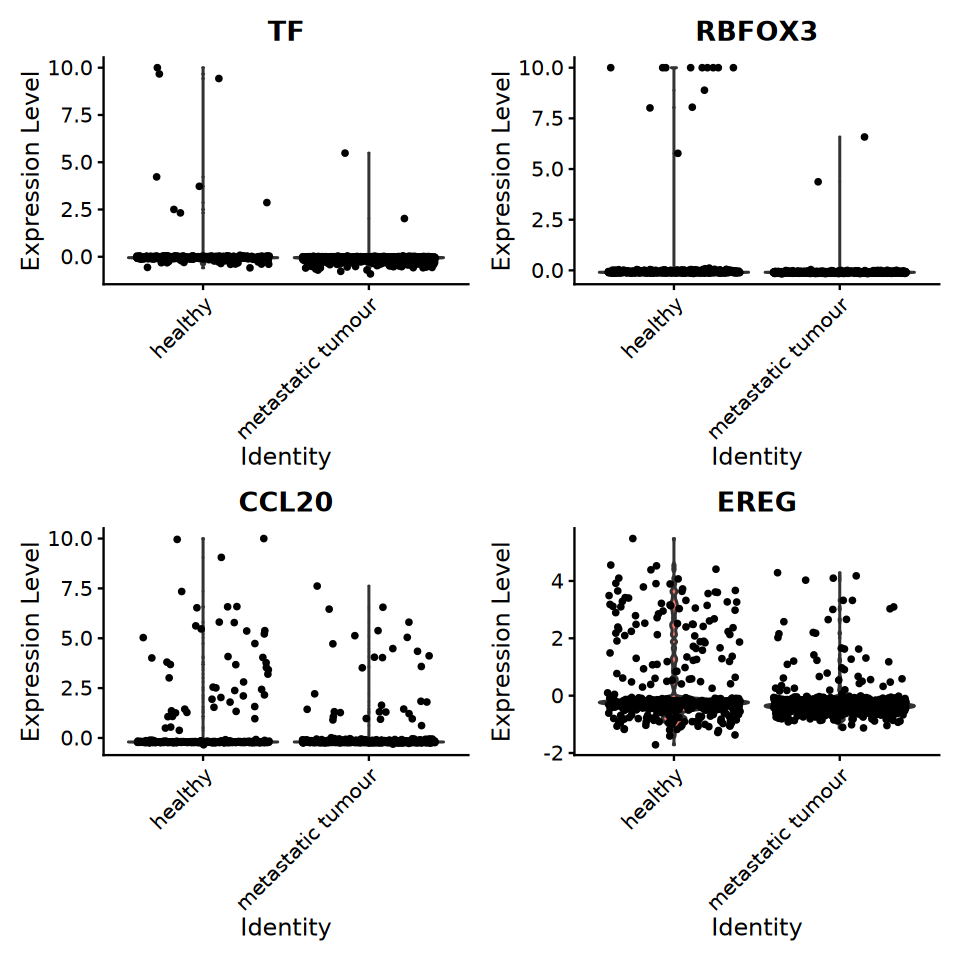

In [37]:
options(repr.plot.width=8, repr.plot.height=8)
VlnPlot(data_mregDC_sub, features = top_genes_mreg[1:4], group.by = "sample_type_major2", ncol = 2)

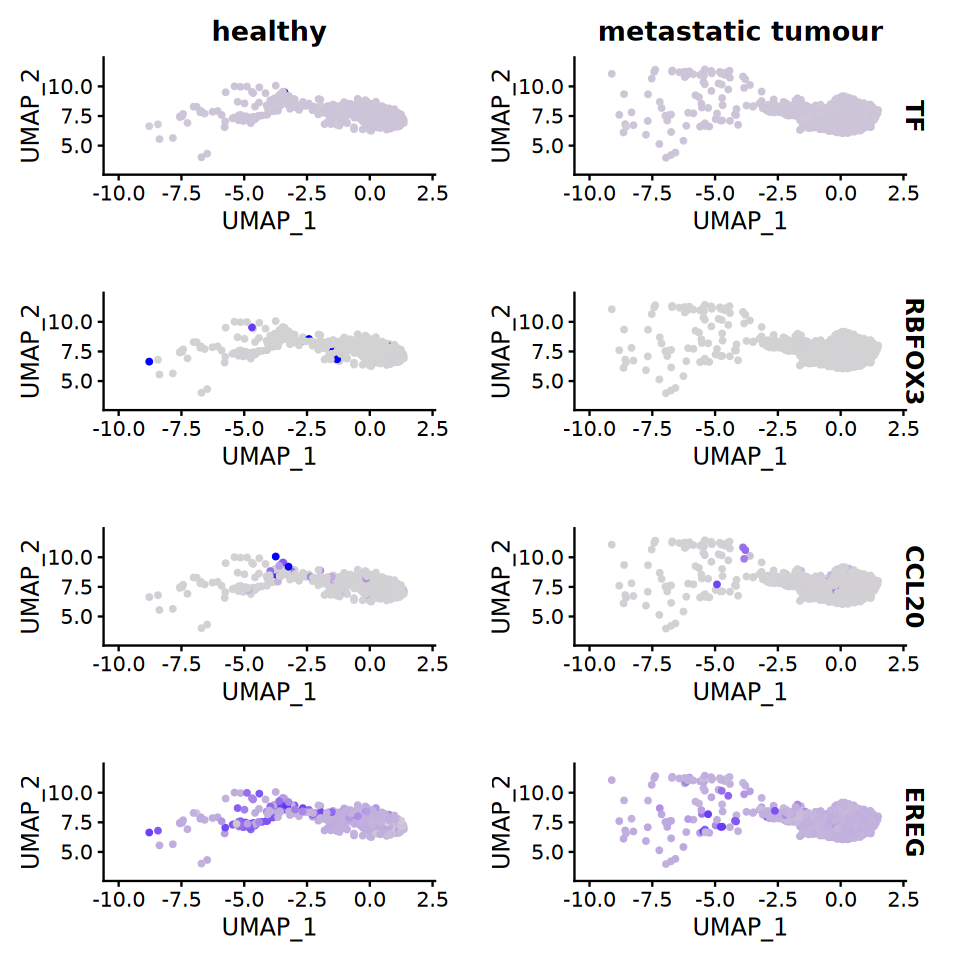

In [38]:
p <- FeaturePlot(data_mregDC_sub, features = top_genes_mreg[1:4], split.by = "sample_type_major2")
#ggsave("mregDEGfeatureplot.png", p, width = 8, height = 7, dpi = 300)
p

* TF ->Transferrin encodes a glycoprotein responsible for transporting iron from the liver, intestine, and reticuloendothelial system to cells. It maintains iron homeostasis  
 * RBFOX3 -> RNA Binding Fox-1 Homolog 3 encodes a protein primarily expressed in neuronal nuclei, widely known as the neuronal marker NeuN.
 * CCL20 -> C-C Motif Chemokine Ligand 20 encodes a small cytokine that acts as a chemoattractant for immune cells, particularly lymphocytes, by binding solely to the CCR6 receptor. 
* EREG -> encodes Epiregulin (EPR), a secreted protein and member of the epidermal growth factor (EGF) family, which acts as a ligand for the Epidermal Growth Factor Receptor (EGFR).



# Create a DEG list (healthy vs primary) of the cDC2s

In [39]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "cDC2"

data_cDC2 <- subset(
  x = data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [40]:
#Confirm that our subsetted data only has our cells of interest
table(data_cDC2@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0  17166      0 

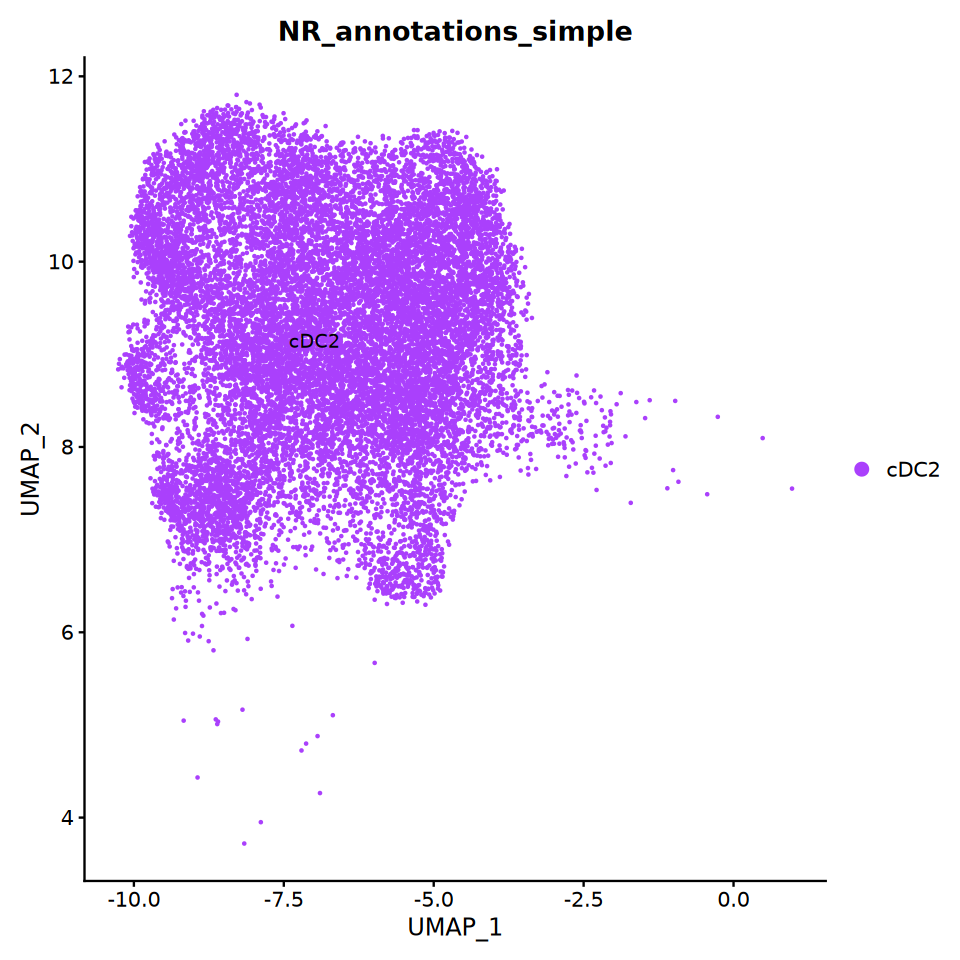

In [41]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_cDC2, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

Set Identities for the sample column

In [42]:
# Set the cell identities to the "sample" metadata column
Idents(data_cDC2) <- data_cDC2@meta.data$sample_type_major2

# Confirm
table(Idents(data_cDC2))


          ascites           healthy metastatic tumour    primary tumour 
             2242              2188              3172              9564 

In [43]:
#subset further to only have primary and metastatic data
data_cDC2_sub <- subset(data_cDC2,
subset = sample_type_major2 %in% c("healthy", "metastatic tumour"))


In [44]:
#Confirm that our subsetted data only has our states of interest
table(data_cDC2_sub@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
                0              2188              3172                 0 

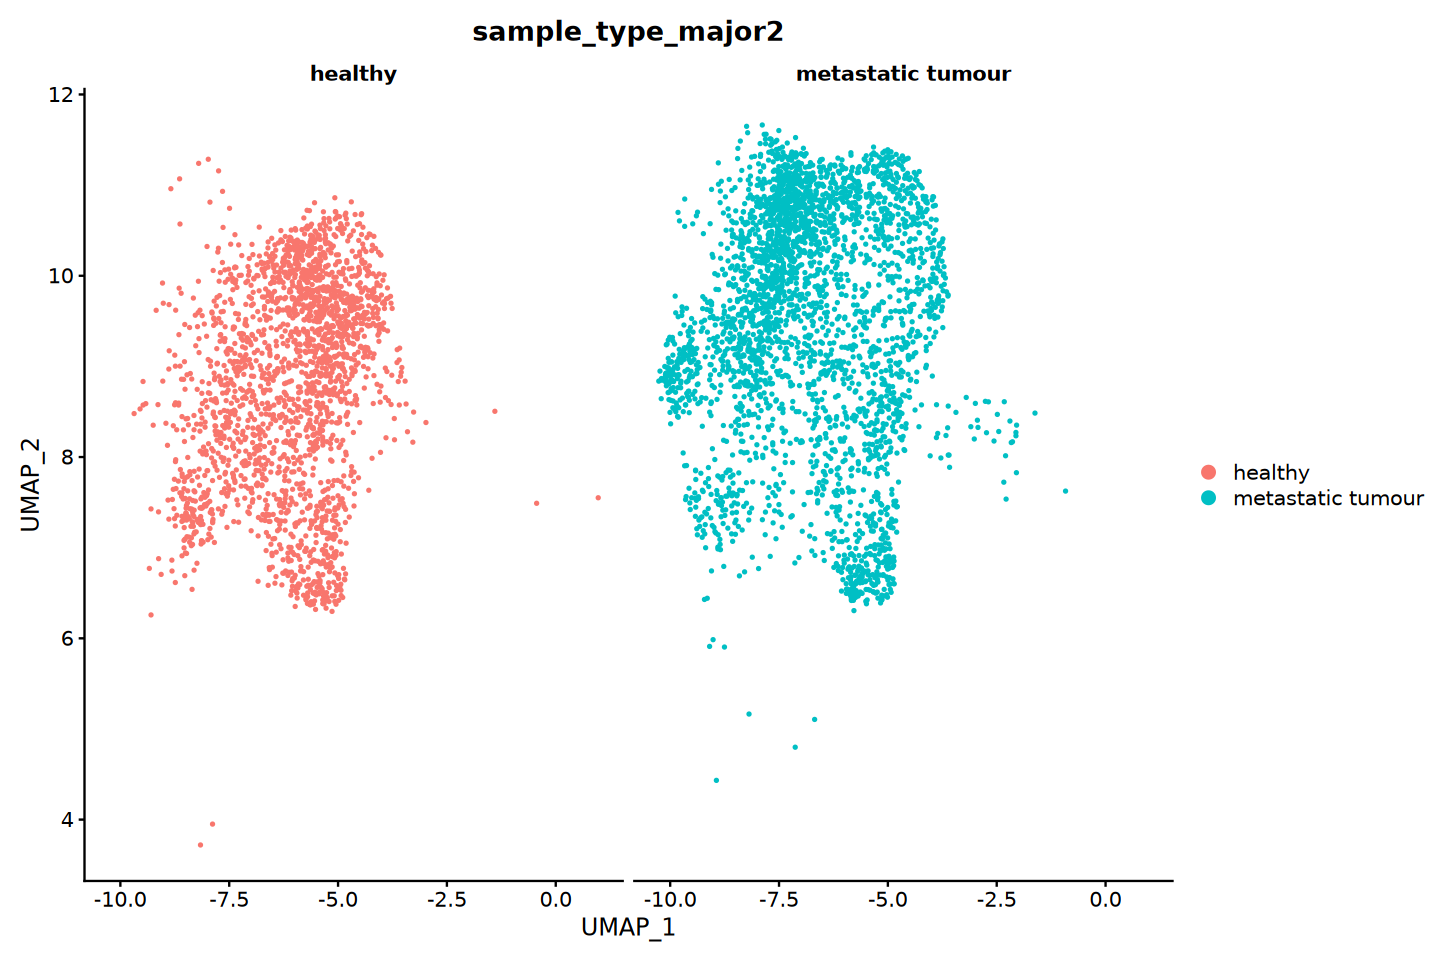

In [45]:
options(repr.plot.width= 12, repr.plot.height= 8)
DimPlot(data_cDC2_sub, reduction = "umap", group.by = "sample_type_major2", repel = TRUE, split.by = "sample_type_major2")

In [46]:
#confirm our subset counts
table(data_cDC2_sub@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0   5360      0 

Run Differential Expression between two states

In [47]:
# Define which two states to compare
group1 <- "healthy"   # upregulated genes will be positive logFC in this group
group2 <- "metastatic tumour"

deg_res_dc2 <- FindMarkers(
  object = data_cDC2_sub,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25,   # only genes with |log2FC| >= 0.25
  max.cells.per.ident = Inf,
  random.seed = 777        
)

head(deg_res_dc2)


Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RPS17,0.000000e+00,6.581173,0.840,0.295,0.000000e+00
LMNA,9.740899e-178,3.215782,0.626,0.293,1.700761e-174
IFITM2,1.034647e-104,-2.453215,0.371,0.640,1.806493e-101
ZC3H12C,3.580248e-96,4.364811,0.367,0.172,6.251113e-93
IDO2,4.486087e-95,2.000095,0.122,0.076,7.832707e-92
CYBB,8.340699e-92,-1.771159,0.351,0.659,1.456286e-88


In [48]:
deg_sig_dc2 <- subset(
  deg_res_dc2,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_dc2[order(deg_sig_dc2$avg_log2FC, decreasing = TRUE), ], n = 10)


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RPS17,0.000000e+00,6.581173,0.840,0.295,0.000000e+00
HBA1,2.657856e-35,6.096623,0.103,0.101,4.640616e-32
RBFOX3,8.266174e-17,5.575480,0.116,0.043,1.443274e-13
ITGB8,5.509716e-45,5.522357,0.113,0.089,9.619965e-42
KLRB1,2.849772e-33,4.790917,0.118,0.050,4.975702e-30
CCL18,1.286528e-12,4.619408,0.224,0.064,2.246279e-09
ZC3H12C,3.580248e-96,4.364811,0.367,0.172,6.251113e-93
THEMIS,2.625473e-23,4.285193,0.152,0.079,4.584077e-20
TBC1D4,1.271842e-10,4.159561,0.055,0.107,2.220635e-07


Quick Visualisation

In [49]:
top_genes_dc2 <- rownames(head(deg_sig_dc2[order(deg_sig_dc2$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_dc2

[1] "RPS17"   "HBA1"    "RBFOX3"  "ITGB8"   "KLRB1"   "CCL18"   "ZC3H12C"
 [8] "THEMIS"  "TBC1D4"  "CXCL3"

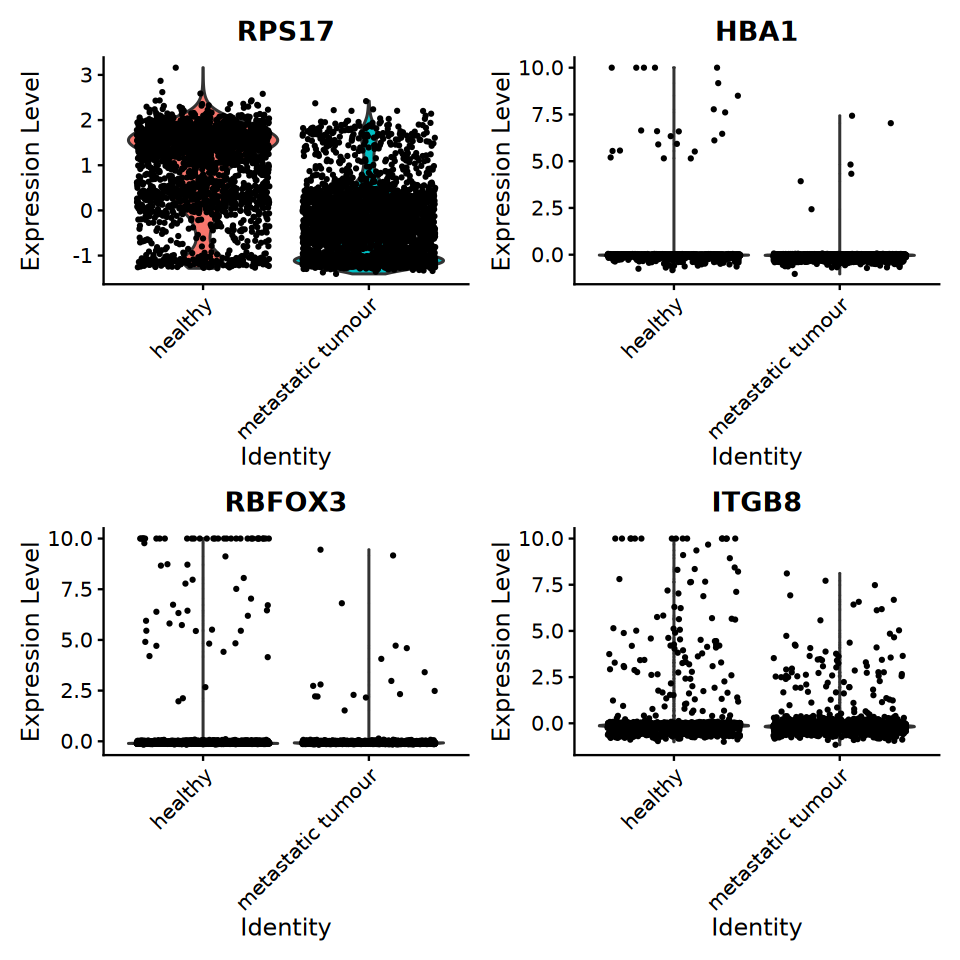

In [50]:
options(repr.plot.width=8, repr.plot.height=8)
VlnPlot(data_cDC2_sub, features = top_genes_dc2[1:4], group.by = "sample_type_major2", pt.size = 0.5, ncol = 2)

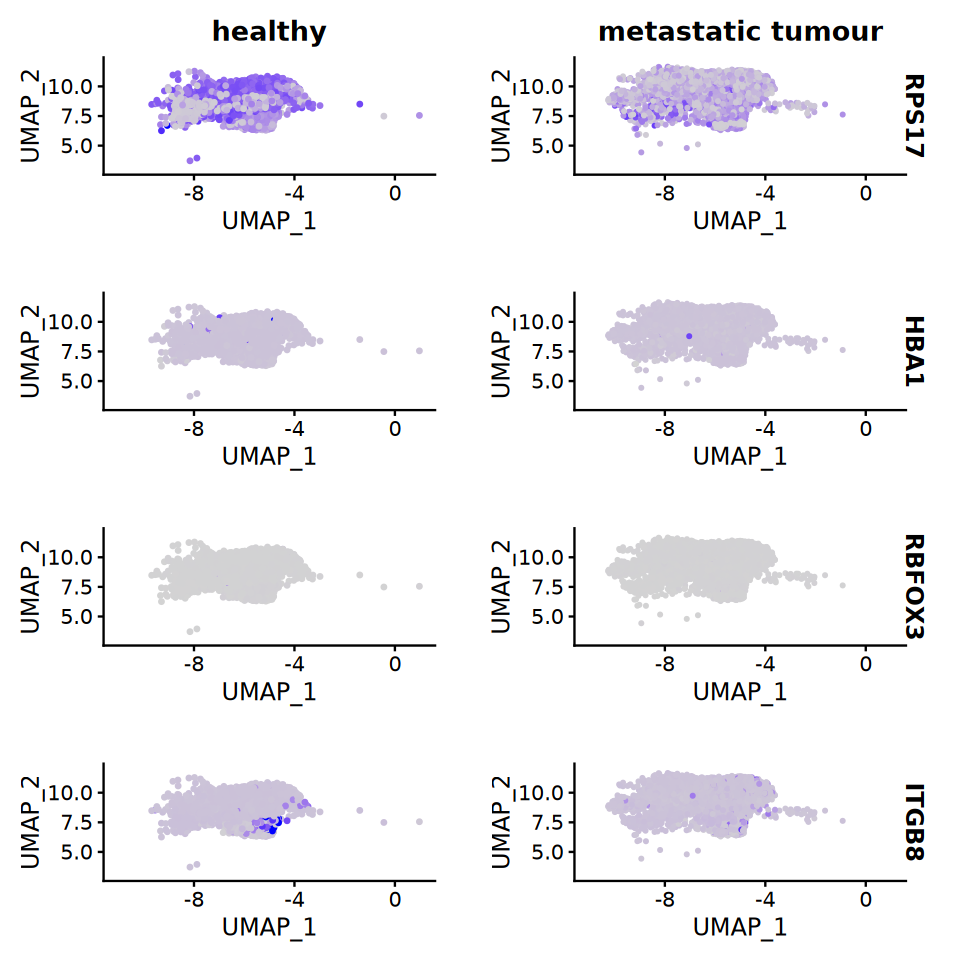

In [51]:
FeaturePlot(data_cDC2_sub, features = top_genes_dc2[1:4], split.by = "sample_type_major2")

* RPS17-> Ribosomal Protein S17 encodes a protein component of the 40S small ribosomal subunit, essential for protein synthesis.
* HBA1 -> Hemoglobin Subunit Alpha 1 provides instructions for making alpha-globin, a component of adult hemoglobin (HbA).
* RBFOX3 -> RNA Binding Fox-1 Homolog 3 encodes a protein primarily expressed in neuronal nuclei, widely known as the neuronal marker NeuN.
* ITGB8 -> Integrin Subunit Beta 8) encodes a single-pass type I membrane protein that forms a heterodimeric integrin complex


# Create a DEG list (primary vs mets) of the cDC1s

In [52]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "cDC1"

data_cDC1 <- subset(
  x = data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [53]:
#Confirm that our subsetted data only has our cells of interest
table(data_cDC1@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  6670      0      0 

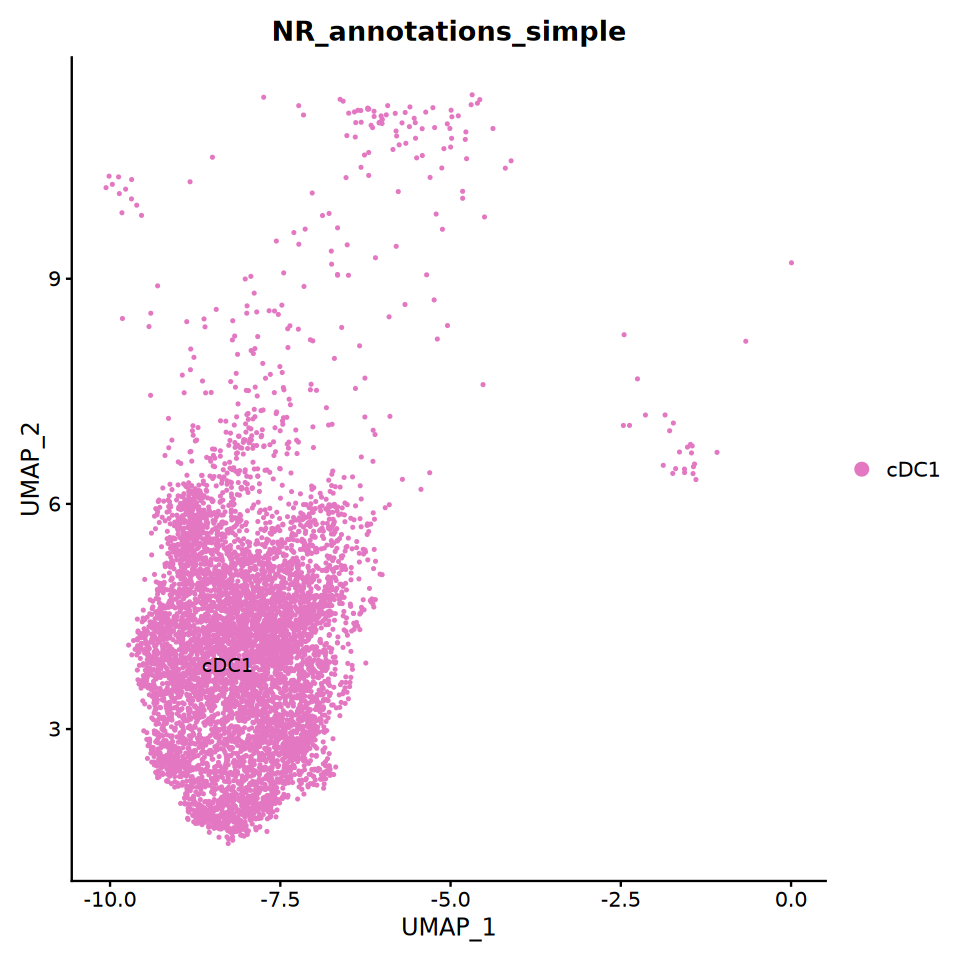

In [54]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_cDC1, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

Set identities for the sample column

In [55]:
# Set the cell identities to the "sample" metadata column
Idents(data_cDC1) <- data_cDC1@meta.data$sample_type_major2

# Confirm
table(Idents(data_cDC1))


          ascites           healthy metastatic tumour    primary tumour 
             1025               705              1399              3541 

In [61]:
#subset further to only have primary and metastatic data
data_cDC1_sub <- subset(data_cDC1,
subset = sample_type_major2 %in% c("healthy", "metastatic tumour"))

In [62]:
#Confirm that our subsetted data only has our states of interest
table(data_cDC1_sub@meta.data$sample_type_major2)


          ascites           healthy metastatic tumour    primary tumour 
                0               705              1399                 0 

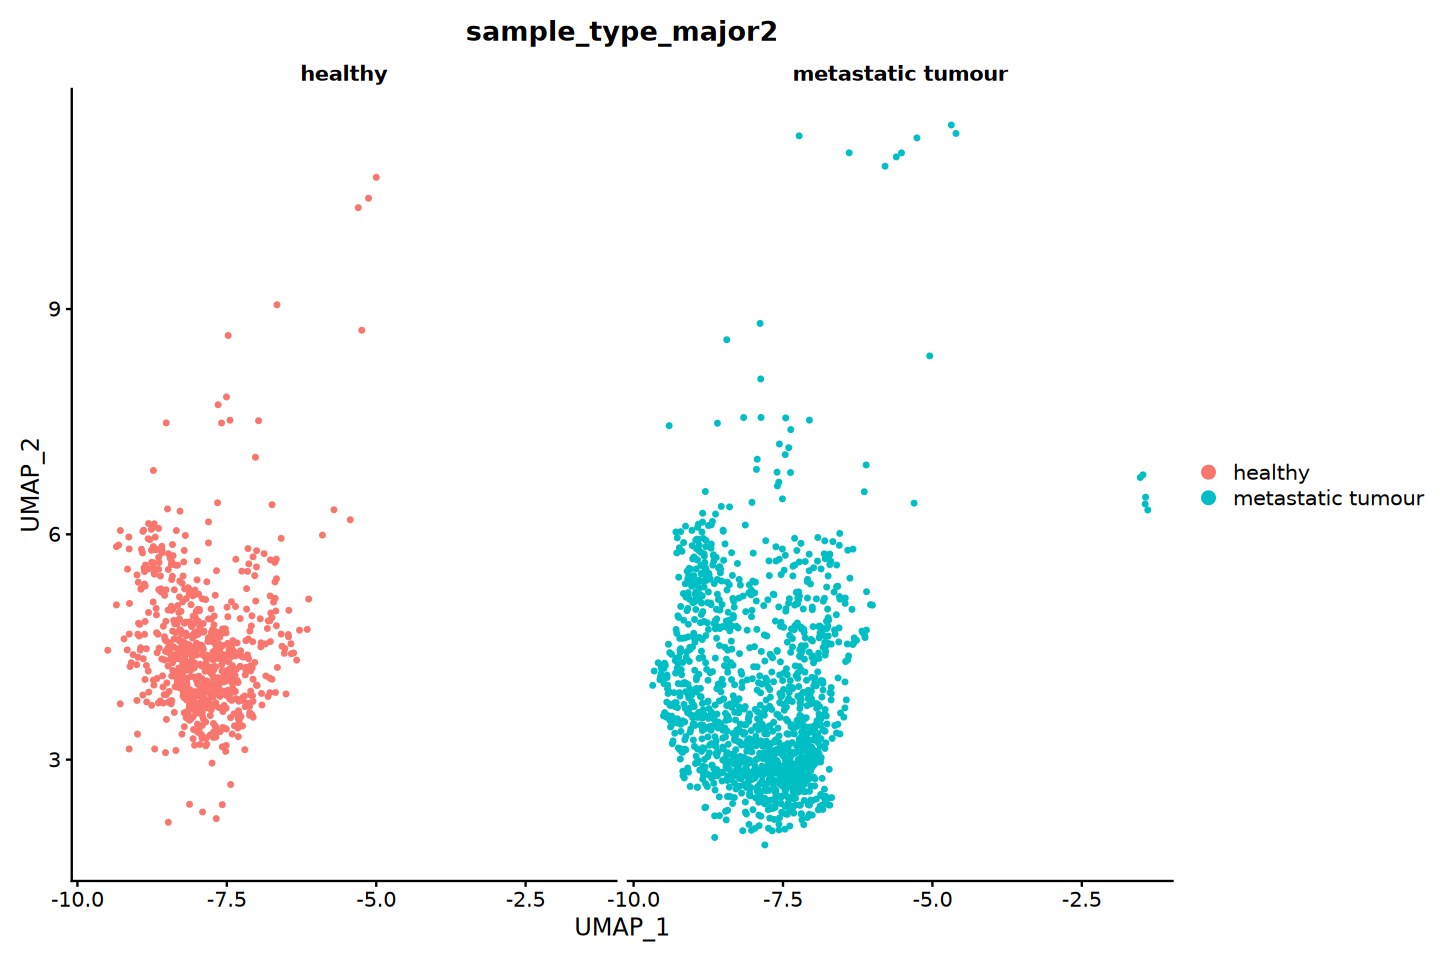

In [63]:
options(repr.plot.width= 12, repr.plot.height= 8)
DimPlot(data_cDC1_sub, reduction = "umap", group.by = "sample_type_major2", repel = TRUE, split.by = "sample_type_major2")

In [59]:
#confirm our cell counts
table(data_cDC1_sub@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  4246      0      0 

Run Differential Expression between the states

In [66]:
# Define which two states to compare
group1 <- "healthy"   # upregulated genes will be positive logFC in this group
group2 <- "metastatic tumour"

deg_res_dc1 <- FindMarkers(
  object = data_cDC1_sub,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25,   # only genes with |log2FC| >= 0.25
  max.cells.per.ident = Inf,
  random.seed = 777        
)

head(deg_res_dc1)


Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LMNA,2.374532e-64,2.384451,0.742,0.490,4.145932e-61
CCND1,2.960885e-52,-1.891670,0.443,0.743,5.169705e-49
CD81,4.932060e-42,-3.953879,0.284,0.561,8.611378e-39
TCF7L2,6.049576e-39,2.133503,0.255,0.169,1.056256e-35
BACH2,1.065989e-37,2.227030,0.304,0.186,1.861217e-34
PCBP3,2.305396e-34,1.532651,0.139,0.096,4.025222e-31


In [67]:
deg_sig_dc1 <- subset(
  deg_res_dc1,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_dc1[order(deg_sig_dc1$avg_log2FC, decreasing = TRUE), ], n = 10)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RHOB,5.003692e-10,9.052978,0.116,0.128,8.736447e-07
SLC34A2,8.369482e-15,8.607223,0.064,0.131,1.461312e-11
FILIP1L,3.901610e-10,6.239698,0.111,0.114,6.812210e-07
AHRR,4.987400e-30,5.885968,0.380,0.232,8.708000e-27
CD9,1.090127e-17,5.693921,0.150,0.137,1.903362e-14
CREM,1.196848e-11,5.496163,0.355,0.239,2.089697e-08
MT1X,3.071174e-14,4.867707,0.119,0.148,5.362270e-11
CXCR4,2.025772e-15,4.140638,0.489,0.350,3.536998e-12
UST,2.667424e-29,4.021253,0.404,0.278,4.657322e-26


Quick Visualisation

In [69]:
top_genes_dc1 <- rownames(head(deg_sig_dc1[order(deg_sig_dc1$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_dc1

[1] "RHOB"    "SLC34A2" "FILIP1L" "AHRR"    "CD9"     "CREM"    "MT1X"   
 [8] "CXCR4"   "UST"     "ATP13A3"

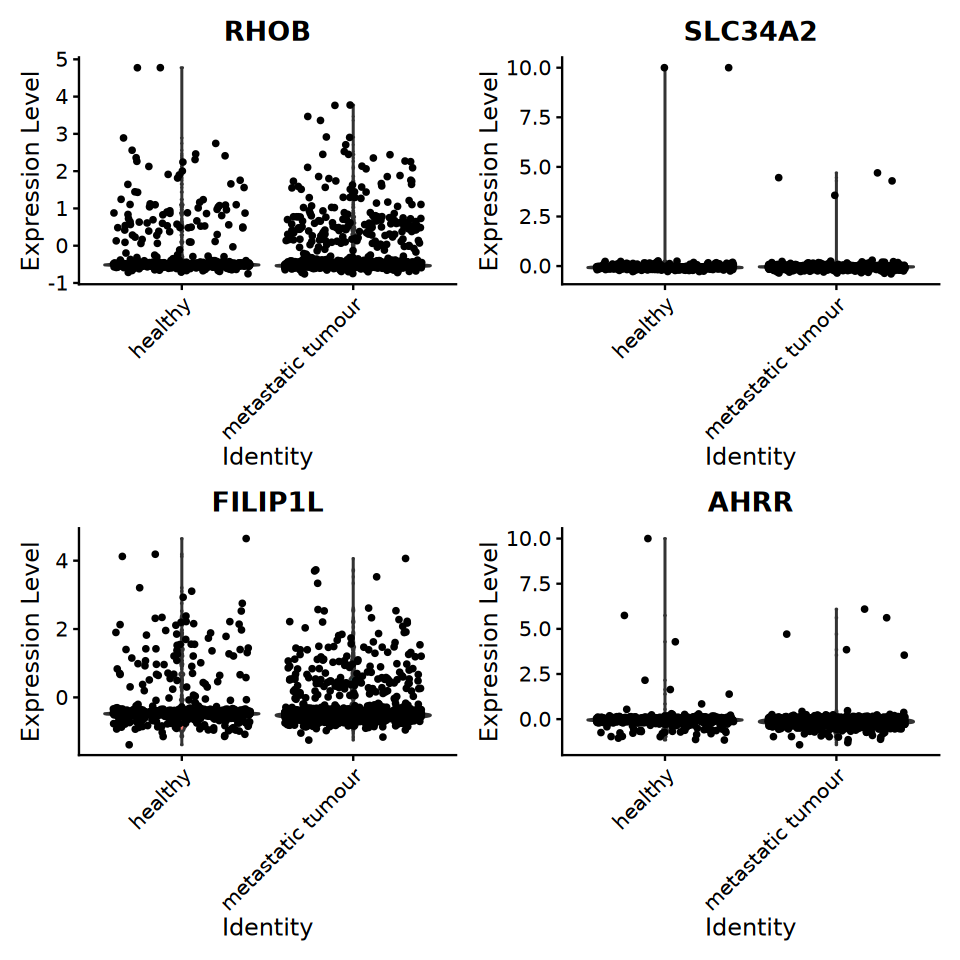

In [70]:
options(repr.plot.width=8, repr.plot.height=8)
VlnPlot(data_cDC1_sub, features = top_genes_dc1[1:4], group.by = "sample_type_major2", ncol = 2) #, pt.size = 0.05

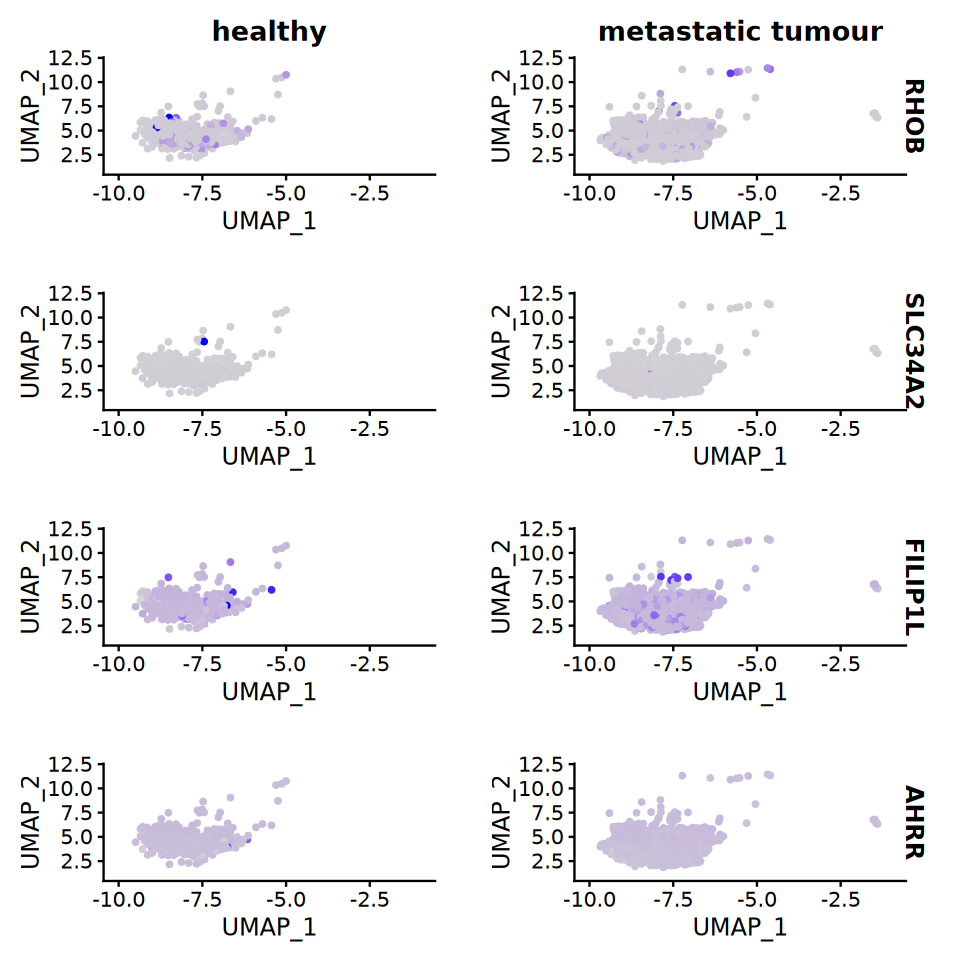

In [71]:
FeaturePlot(data_cDC1_sub, features = top_genes_dc1[1:4], split.by = "sample_type_major2")

* RHOB ->   Ras homolog family member B encodes a small GTPase protein, located on endosomes and the plasma membrane, that acts as a tumor suppressor by regulating actin cytoskeleton, vesicle trafficking, apoptosis, and cell motility
* SLC34A2 -> encodes the NaPi-2b sodium-dependent phosphate cotransporter, which plays a key role in maintaining inorganic phosphate homeostasis. 
* FILIP1L ->  Filamin A Interacting Protein 1 Like gene, functions as a tumor suppressor by inhibiting angiogenesis, cell proliferation, and migration, often while regulating the actin cytoskeleton
* AHRR -> Aryl Hydrocarbon Receptor Repressor encodes a protein that acts as a negative regulator of the aryl hydrocarbon receptor (AhR) signaling pathway


# Trying to make a Volcano Plot

In [72]:
head(deg_res_mreg)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
KIF2A,8.391550e-35,-1.5403342,0.446,0.741,1.465165e-31
PIK3R5,3.865636e-31,0.4814712,0.389,0.186,6.749400e-28
XYLT1,1.238585e-30,1.5678858,0.567,0.311,2.162570e-27
DENND4A,3.240645e-28,1.0955000,0.463,0.284,5.658167e-25
FNDC3B,1.469301e-27,1.3630123,0.397,0.199,2.565399e-24
ATP1B3,1.473209e-27,1.9274458,0.573,0.311,2.572224e-24


In [73]:
mreg_vp <- deg_res_mreg %>%
tibble::rownames_to_column("gene")%>%
arrange(p_val_adj, desc(avg_log2FC))

In [74]:
head(mreg_vp, 10)

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,KIF2A,8.391550e-35,-1.5403342,0.446,0.741,1.465165e-31
2,PIK3R5,3.865636e-31,0.4814712,0.389,0.186,6.749400e-28
3,XYLT1,1.238585e-30,1.5678858,0.567,0.311,2.162570e-27
4,DENND4A,3.240645e-28,1.0955000,0.463,0.284,5.658167e-25
5,FNDC3B,1.469301e-27,1.3630123,0.397,0.199,2.565399e-24
6,ATP1B3,1.473209e-27,1.9274458,0.573,0.311,2.572224e-24
7,ZHX2,3.016118e-26,1.6143942,0.480,0.270,5.266142e-23
8,RASSF4,1.969023e-25,-1.2214157,0.597,0.791,3.437914e-22
9,ABTB2,7.546314e-25,1.3360238,0.340,0.182,1.317586e-21


Create Violin plot - mreg

In [75]:
mreg_vp <- deg_res_mreg%>%
mutate(neglog10_padj = -log10(p_val_adj + 1e-300),
sig = p_val_adj < 0.05 & abs (avg_log2FC) > 0.25
)%>%
tibble::rownames_to_column("gene")

In [76]:
head(mreg_vp)

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,neglog10_padj,sig
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,KIF2A,8.391550e-35,-1.5403342,0.446,0.741,1.465165e-31,30.83411,TRUE
2,PIK3R5,3.865636e-31,0.4814712,0.389,0.186,6.749400e-28,27.17073,TRUE
3,XYLT1,1.238585e-30,1.5678858,0.567,0.311,2.162570e-27,26.66503,TRUE
4,DENND4A,3.240645e-28,1.0955000,0.463,0.284,5.658167e-25,24.24732,TRUE
5,FNDC3B,1.469301e-27,1.3630123,0.397,0.199,2.565399e-24,23.59085,TRUE
6,ATP1B3,1.473209e-27,1.9274458,0.573,0.311,2.572224e-24,23.58969,TRUE


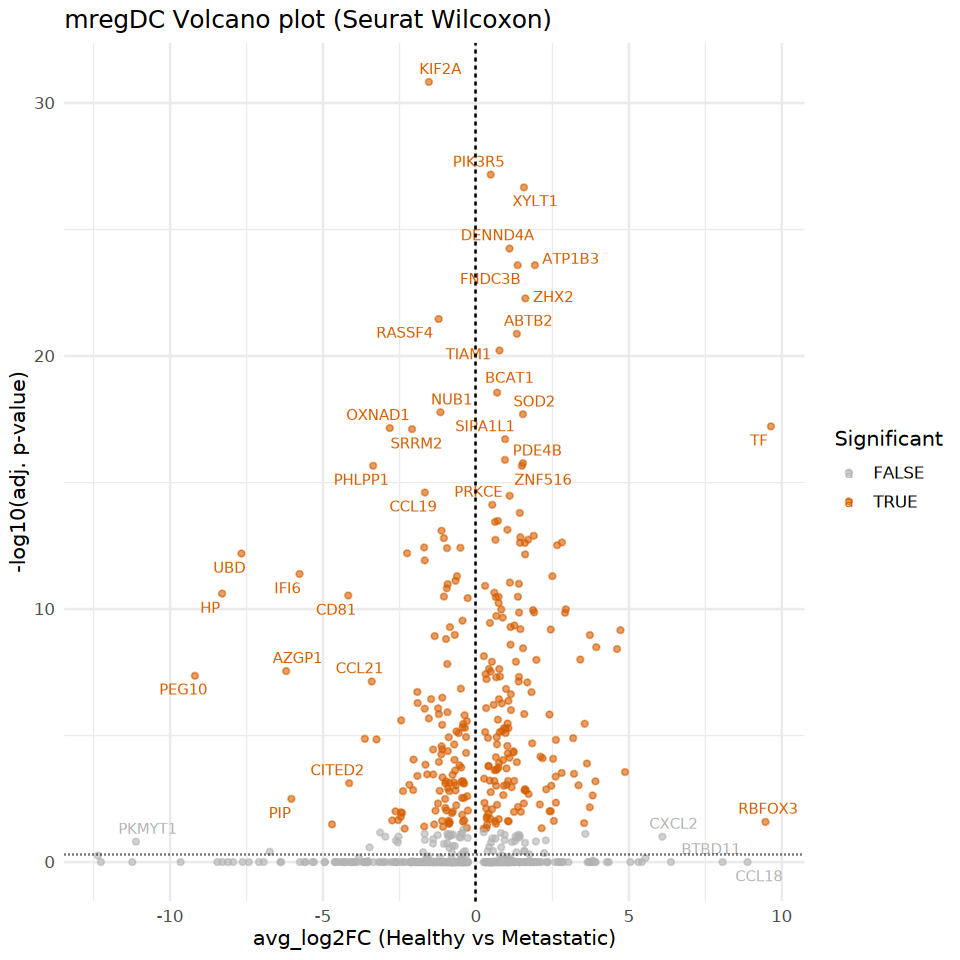

In [77]:

ggplot(mreg_vp, aes(x = avg_log2FC, y = neglog10_padj, color = sig, label = gene)) +
  geom_point(alpha = 0.6, size = 1.2) +
  scale_color_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00")) +
  labs(
    title = "mregDC Volcano plot (Seurat Wilcoxon)",
    x = "avg_log2FC (Healthy vs Metastatic)",
    y = "-log10(adj. p-value)",
    color = "Significant"
  ) +
  geom_text_repel(size = 3,  max.overlaps = 5) +
  geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
  geom_hline(yintercept = c(-log10(0.5)), linetype = "dotted", color = "black") +
  theme_minimal(base_size = 12)

  options(repr.plot.width=12, repr.plot.height=10)


Create Violin plot - cDC1

In [78]:
dc1_vp <- deg_res_dc1%>%
mutate(neglog10_padj = -log10(p_val_adj + 1e-300),
sig = p_val_adj < 0.05 & abs (avg_log2FC) > 0.25
)%>%
tibble::rownames_to_column("gene")

head(dc1_vp)

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,neglog10_padj,sig
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,LMNA,2.374532e-64,2.384451,0.742,0.490,4.145932e-61,60.38238,TRUE
2,CCND1,2.960885e-52,-1.891670,0.443,0.743,5.169705e-49,48.28653,TRUE
3,CD81,4.932060e-42,-3.953879,0.284,0.561,8.611378e-39,38.06493,TRUE
4,TCF7L2,6.049576e-39,2.133503,0.255,0.169,1.056256e-35,34.97623,TRUE
5,BACH2,1.065989e-37,2.227030,0.304,0.186,1.861217e-34,33.73020,TRUE
6,PCBP3,2.305396e-34,1.532651,0.139,0.096,4.025222e-31,30.39521,TRUE


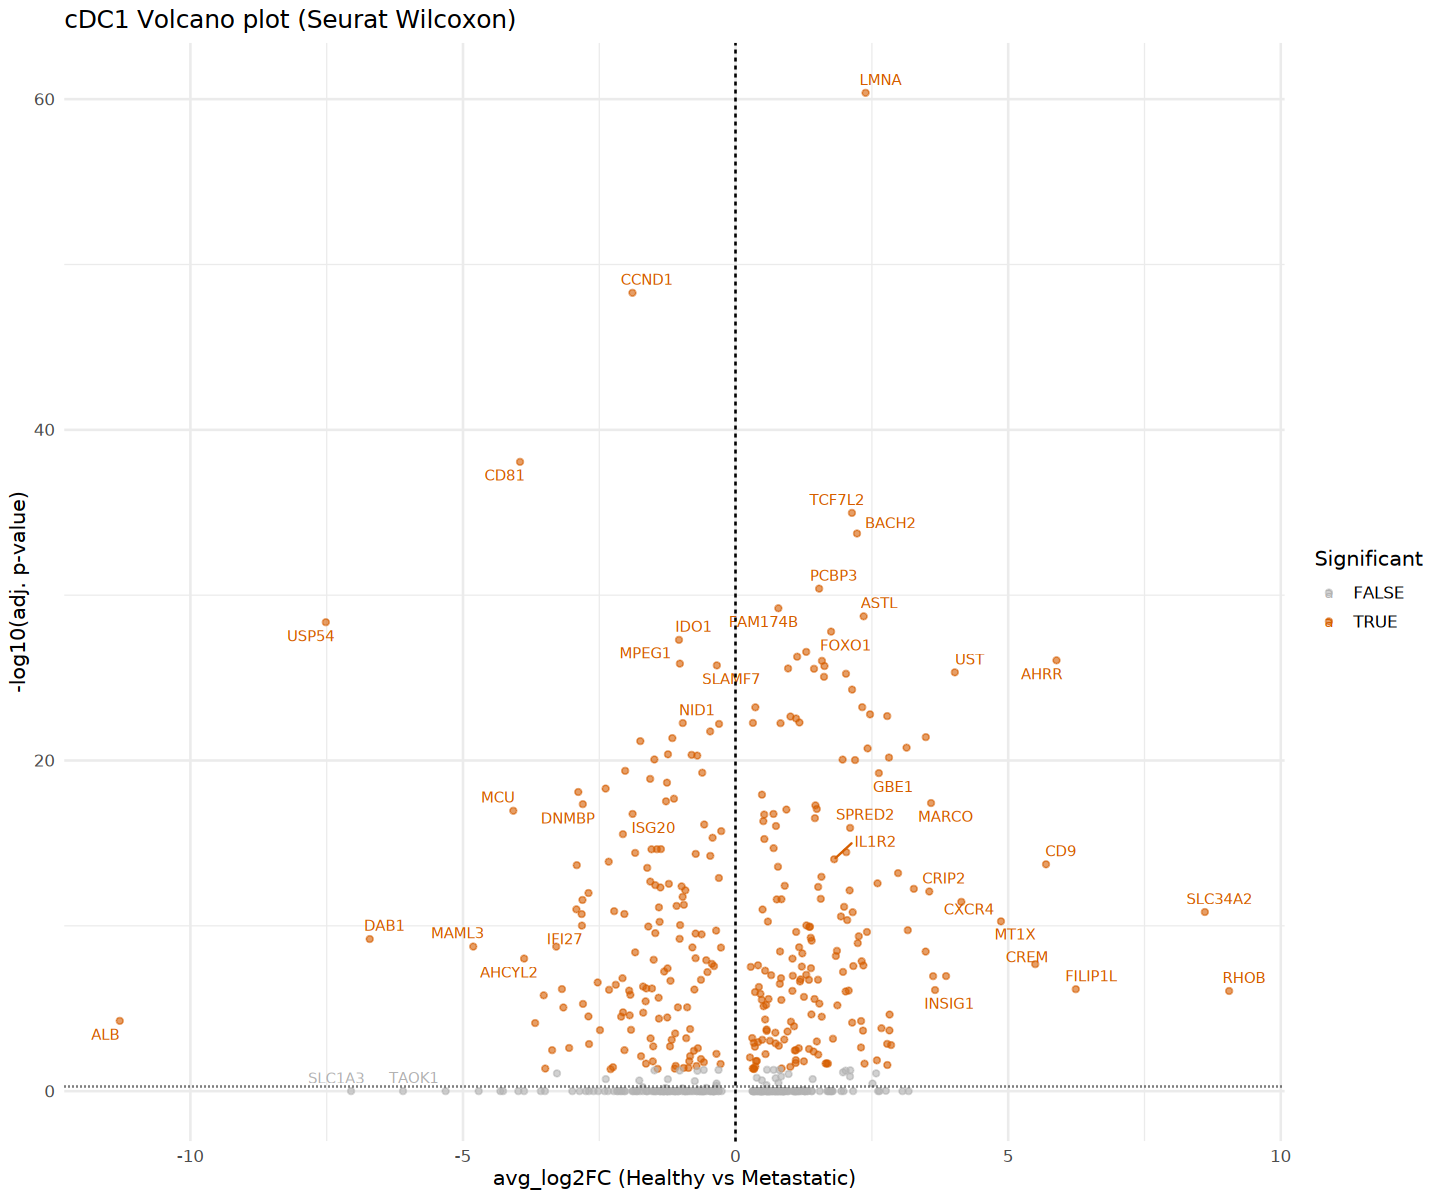

In [80]:

ggplot(dc1_vp, aes(x = avg_log2FC, y = neglog10_padj, color = sig, label = gene)) +
  geom_point(alpha = 0.6, size = 1.2) +
  scale_color_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00")) +
  labs(
    title = "cDC1 Volcano plot (Seurat Wilcoxon)",
    x = "avg_log2FC (Healthy vs Metastatic)",
    y = "-log10(adj. p-value)",
    color = "Significant"
  ) +
  geom_text_repel(size = 3,  max.overlaps = 5) +
  geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
  geom_hline(yintercept = c(-log10(0.5)), linetype = "dotted", color = "black") +
  theme_minimal(base_size = 12)

  options(repr.plot.width=12, repr.plot.height=10)


Create Violin plot - cDC2

In [81]:
dc2_vp <- deg_res_dc2%>%
mutate(neglog10_padj = -log10(p_val_adj + 1e-300),
sig = p_val_adj < 0.05 & abs (avg_log2FC) > 0.25
)%>%
tibble::rownames_to_column("gene")

head(dc2_vp)

,gene,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,neglog10_padj,sig
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,RPS17,0.000000e+00,6.581173,0.840,0.295,0.000000e+00,300.00000,TRUE
2,LMNA,9.740899e-178,3.215782,0.626,0.293,1.700761e-174,173.76936,TRUE
3,IFITM2,1.034647e-104,-2.453215,0.371,0.640,1.806493e-101,100.74316,TRUE
4,ZC3H12C,3.580248e-96,4.364811,0.367,0.172,6.251113e-93,92.20404,TRUE
5,IDO2,4.486087e-95,2.000095,0.122,0.076,7.832707e-92,91.10609,TRUE
6,CYBB,8.340699e-92,-1.771159,0.351,0.659,1.456286e-88,87.83675,TRUE


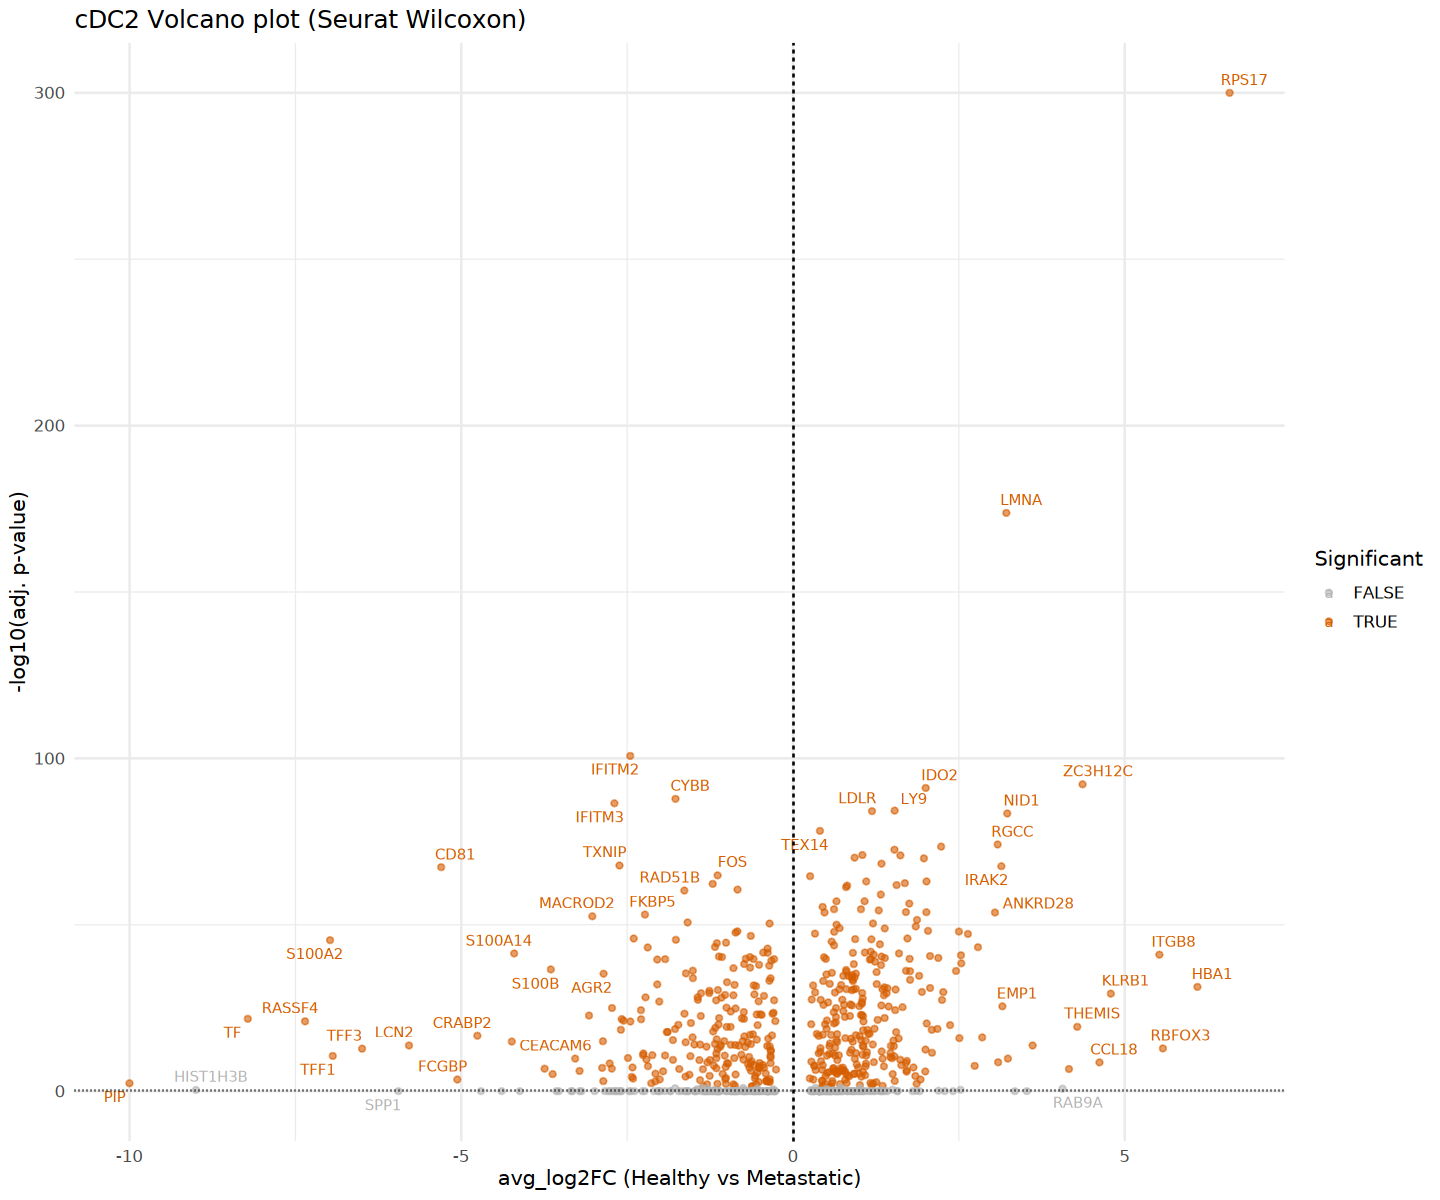

In [82]:

ggplot(dc2_vp, aes(x = avg_log2FC, y = neglog10_padj, color = sig, label = gene)) +
  geom_point(alpha = 0.6, size = 1.2) +
  scale_color_manual(values = c("FALSE" = "grey70", "TRUE" = "#D55E00")) +
  labs(
    title = "cDC2 Volcano plot (Seurat Wilcoxon)",
    x = "avg_log2FC (Healthy vs Metastatic)",
    y = "-log10(adj. p-value)",
    color = "Significant"
  ) +
  geom_text_repel(size = 3,  max.overlaps = 5) +
  geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
  geom_hline(yintercept = c(-log10(0.5)), linetype = "dotted", color = "black") +
  theme_minimal(base_size = 12)

  options(repr.plot.width=12, repr.plot.height=10)


# Dot Plot

In [67]:
options(repr.plot.width= 20, repr.plot.height= 5)

In [76]:
top_genes_dc1 <- rownames(head(deg_sig_dc1[order(deg_sig_dc1$avg_log2FC, decreasing = TRUE), ], 20))
top_genes_dc1

[1] "RHOB"    "SLC34A2" "CSF1"    "CEACAM6" "CD9"     "KSR1"    "TWISTNB"
 [8] "AHRR"    "MT1X"    "RASA2"   "STARD13" "SDC1"    "FOXO3"   "A2M"    
[15] "LPCAT1"  "GPX3"    "EPB41L3" "CYB5A"   "FRMD4A"  "BHLHE41"

Warning message:
“Scaling data with a low number of groups may produce misleading results”


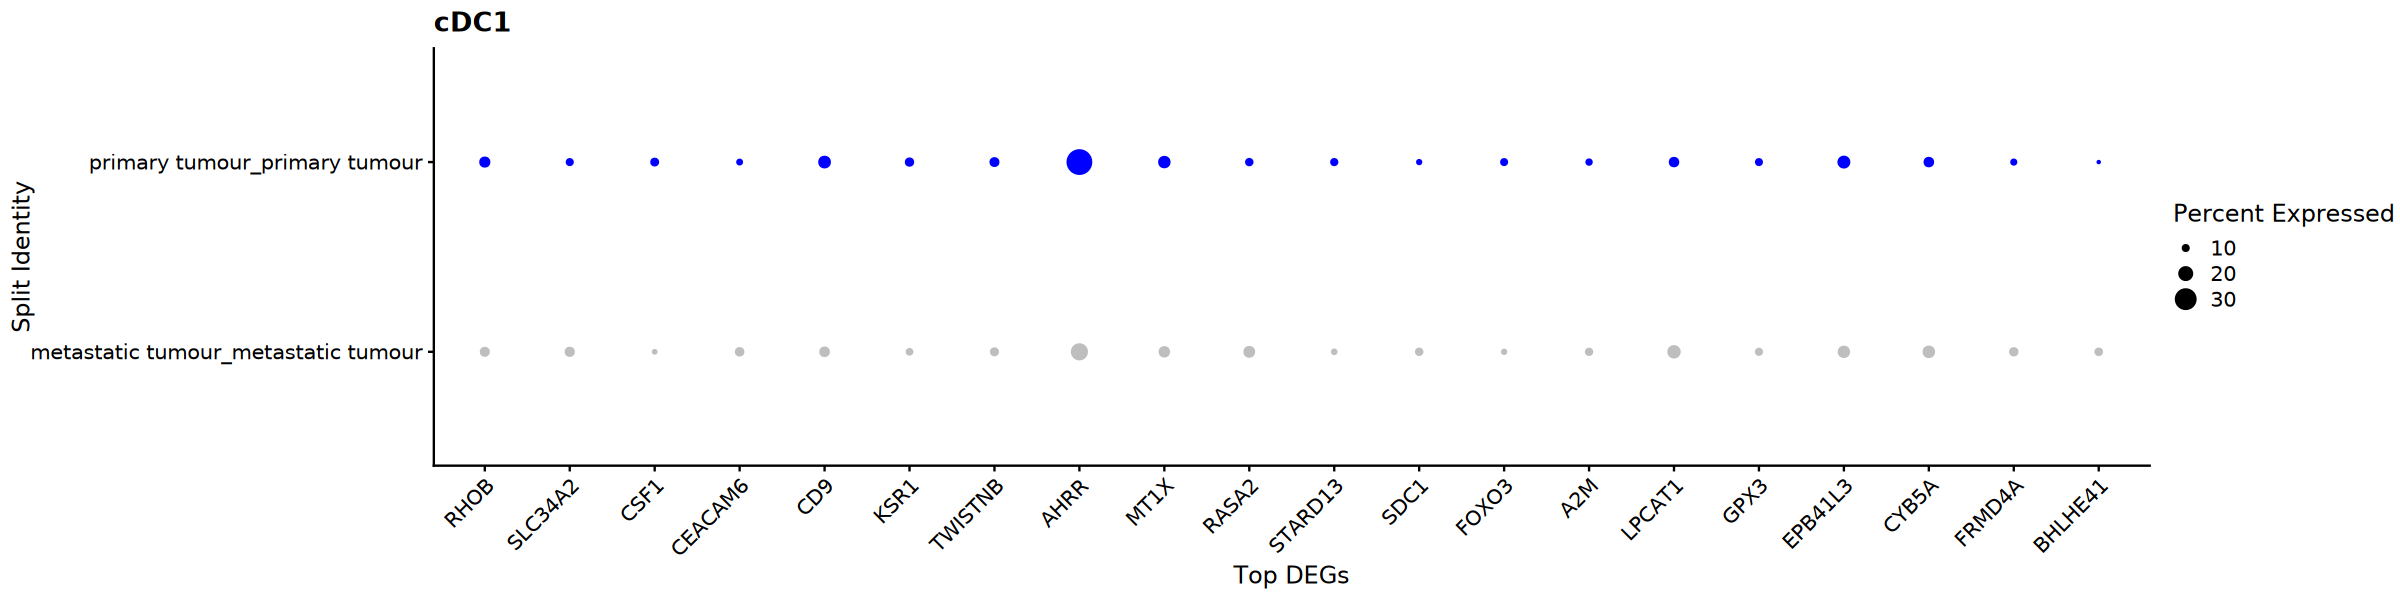

In [77]:
# SplitDotPlotGG has been replaced with the `split.by` parameter for DotPlot
p <- DotPlot(data_cDC1_sub, features = top_genes_dc1[1:20], split.by = "sample_type_major2") + RotatedAxis()
p + labs(title = "cDC1", x = "Top DEGs")

In [ ]:
DotPlot(data_cDC1_sub, features = deg_res_dc1, split.by = "sample_type_major2") + RotatedAxis()

Warning message:
“The following requested variables were not found (10 out of 1758 shown): 1.23541208033858e-129, 3.52208475873295e-42, 6.13425326745766e-37, 1.61883331563508e-30, 3.1692750550465e-25, 6.14236922504983e-25, 5.97745306919556e-24, 2.02095698740908e-22, 7.36547110598023e-20, 2.05786056489954e-19”
Warning message:
“Removing 4246 cells missing data for vars requested”


ERROR: Error in `$<-.data.frame`(`*tmp*`, "id", value = structure(c(`GSE154826_D1_AACCGCGAGAAGGGTA-1` = 1L, : replacement has 4246 rows, data has 0


: 